## QUESTION 2
## Seasonal surface water in Vijayawada, 2001–2021

In [1]:
import os
import io
import requests

import ee
import geemap
import geemap.colormaps as cm
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from scipy import stats
from PIL import Image

In [2]:
PROJECT_ID = "deft-manifest-510708-q3"

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)

print("Google Earth Engine initialized successfully.")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Google Earth Engine initialized successfully.


In [3]:
START_YEAR = 2001
END_YEAR = 2021                      # GSW v1.4 ends in 2021
YEARS = list(range(START_YEAR, END_YEAR + 1))

# Folder containing the boundary file
data_path = r"C:\Users\ANAGHA K N\Desktop\UISA_2026"

BOUNDARY_PATH = os.path.join(data_path, "Vijayawada_Boundary.geojson")

# All figures, the GIF and the CSV are saved here (inside your data folder)
OUT_DIR = os.path.join(data_path, "vijayawada_gsw_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

print("Folder exists:", os.path.exists(data_path))
print("Boundary file exists:", os.path.exists(BOUNDARY_PATH))

# State this in your webpage (assignment requirement)
BOUNDARY_SOURCE = (
    "Vijayawada municipal boundary, DataMeet Municipal Spatial Data "
    "(github.com/datameet/Municipal_Spatial_Data), CC BY-SA 2.5 India"
)
DATASET_SOURCE = (
    "Pekel et al. (2016); JRC Global Surface Water v1.4 "
    "(JRC/GSW1_4/YearlyHistory), Google Earth Engine"
)

print("Years:", YEARS[0], "to", YEARS[-1], f"({len(YEARS)} years)")
print("Outputs will be saved in:", os.path.abspath(OUT_DIR))

Folder exists: True
Boundary file exists: True
Years: 2001 to 2021 (21 years)
Outputs will be saved in: C:\Users\ANAGHA K N\Desktop\UISA_2026\vijayawada_gsw_outputs


### Load the Vijayawada boundary

In [4]:
vijayawada_gdf = gpd.read_file(BOUNDARY_PATH).to_crs(epsg=4326)

# This boundary file stores 3-D coordinates (x, y, z). Earth Engine only accepts
# 2-D geometries and raises "Invalid GeoJSON geometry" otherwise, so drop the z value.
try:
    from shapely import force_2d
except ImportError:                                   # older shapely versions
    from shapely.ops import transform
    force_2d = lambda geom: transform(lambda x, y, z=None: (x, y), geom)

vijayawada_gdf["geometry"] = vijayawada_gdf.geometry.apply(force_2d)
print("Geometry has z-values:", vijayawada_gdf.geometry.has_z.any())

# Merge into a single geometry in case the file has more than one feature
vijayawada_gdf = vijayawada_gdf.dissolve().reset_index(drop=True)[["geometry"]]

city_area_km2_local = vijayawada_gdf.to_crs(epsg=32644).geometry.area.iloc[0] / 1e6
print(f"City boundary area (GeoPandas, UTM 44N): {city_area_km2_local:.2f} km²")

vijayawada = geemap.geopandas_to_ee(vijayawada_gdf)
vijayawada_geom = vijayawada.geometry()
region_bounds = vijayawada_geom.bounds()

vijayawada_gdf

Geometry has z-values: False
City boundary area (GeoPandas, UTM 44N): 61.50 km²


,geometry
0,"POLYGON ((80.66727 16.56574, 80.66317 16.55412..."


In [5]:
Map = geemap.Map()
Map.centerObject(vijayawada, 11)
Map.addLayer(vijayawada, {"color": "blue"}, "Vijayawada boundary")
Map

Map(center=[16.521661790351352, 80.63998335517861], controls=(WidgetControl(options=['position', 'transparent_…

### Load the Global Surface Water yearly collection

In [6]:
gsw = ee.ImageCollection("JRC/GSW1_4/YearlyHistory")

print("Total images in the collection:", gsw.size().getInfo())

first = ee.Image(gsw.first())
print("Bands:", first.bandNames().getInfo())
print("Properties of the first image:", first.propertyNames().getInfo())

Total images in the collection: 38
Bands: ['waterClass']
Properties of the first image: ['system:time_start', 'year', 'system:footprint', 'waterClass_class_names', 'waterClass_class_palette', 'system:version', 'system:id', 'waterClass_class_values', 'system:asset_size', 'system:index', 'system:bands', 'system:band_names']


In [7]:
def get_year_image(year):
    start = ee.Date.fromYMD(year, 1, 1)
    end = start.advance(1, "year")
    img = ee.Image(
        gsw.filterDate(start, end).first()
    )
    return (
        img.select("waterClass")
        .clipToCollection(vijayawada)
        .set("year", year)
        .set("system:time_start", start.millis())
    )


annual_images = [get_year_image(y) for y in YEARS]

annual_water = (
    ee.ImageCollection.fromImages(annual_images)
    .sort("system:time_start")
)

print("Number of annual images:", annual_water.size().getInfo())   # expected: 21

Number of annual images: 21


In [8]:
SEASONAL_COLOR = "#00c2ff"
PERMANENT_COLOR = "#08306b"
NODATA_COLOR = "#bdbdbd"
NOTWATER_COLOR = "#f5f1e6"

# index 0..3 -> no data, not water, seasonal, permanent
CLASS_PALETTE = [NODATA_COLOR, NOTWATER_COLOR, SEASONAL_COLOR, PERMANENT_COLOR]
class_vis = {"min": 0, "max": 3, "palette": CLASS_PALETTE}

# For the interactive slider we show only water (classes 2 and 3) on top of the basemap
slider_vis = {"min": 2, "max": 3, "palette": [SEASONAL_COLOR, PERMANENT_COLOR]}

def water_only(img):
    return (
        img.updateMask(img.gte(2))
        .copyProperties(img, ["system:time_start", "year"])
    )

water_slider_collection = annual_water.map(water_only)

In [9]:
img_start = ee.Image(annual_water.filter(ee.Filter.eq("year", START_YEAR)).first())
img_end = ee.Image(annual_water.filter(ee.Filter.eq("year", END_YEAR)).first())

Map = geemap.Map()
Map.centerObject(vijayawada, 11)
Map.add_basemap("SATELLITE")
Map.addLayer(img_start, class_vis, f"Water class {START_YEAR}")
Map.addLayer(img_end, class_vis, f"Water class {END_YEAR}", shown=False)
Map.addLayer(vijayawada, {"color": "white"}, "Vijayawada boundary")
Map

Map(center=[16.521661790353456, 80.6399833551778], controls=(WidgetControl(options=['position', 'transparent_b…

### Quantifying the annual area of seasonal surface water

In [10]:
def yearly_areas(img):
    area_km2 = ee.Image.pixelArea().divide(1e6)

    bands = ee.Image.cat([
        area_km2.multiply(img.eq(2)).rename("seasonal_km2"),
        area_km2.multiply(img.eq(3)).rename("permanent_km2"),
        area_km2.multiply(img.eq(1)).rename("notwater_km2"),
        area_km2.multiply(img.eq(0)).rename("nodata_km2"),
        area_km2.rename("total_km2"),
    ])

    sums = bands.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=vijayawada_geom,
        scale=30,
        maxPixels=1e9,
        tileScale=4
    )

    return ee.Feature(None, sums).set("year", img.get("year"))


area_fc = ee.FeatureCollection(annual_water.map(yearly_areas))

rows = [f["properties"] for f in area_fc.getInfo()["features"]]
df = pd.DataFrame(rows).sort_values("year").reset_index(drop=True)
df["year"] = df["year"].astype(int)

df.head()

,nodata_km2,notwater_km2,permanent_km2,seasonal_km2,total_km2,year
0,0.127801,3.235227,1.949705,0.712639,61.547408,2001
1,0.104804,3.729089,1.674996,0.516483,61.547408,2002
2,0.617988,3.397866,1.637313,0.372206,61.547408,2003
3,0.000858,3.686601,1.639537,0.698376,61.547408,2004
4,0.681767,1.999198,1.601794,1.742614,61.547408,2005


In [11]:
df["water_total_km2"] = df["seasonal_km2"] + df["permanent_km2"]
df["seasonal_pct_city"] = 100 * df["seasonal_km2"] / df["total_km2"]
df["permanent_pct_city"] = 100 * df["permanent_km2"] / df["total_km2"]
df["pct_nodata"] = 100 * df["nodata_km2"] / df["total_km2"]

# Consistency check: classes should sum to the total area
check = (
    df[["seasonal_km2", "permanent_km2", "notwater_km2", "nodata_km2"]].sum(axis=1)
    - df["total_km2"]
).abs().max()
print(f"Largest mismatch between class sum and total area: {check:.6f} km²")

print(f"City area from Earth Engine: {df['total_km2'].iloc[0]:.2f} km²")
print(f"City area from GeoPandas   : {city_area_km2_local:.2f} km²")

df.round(3)

Largest mismatch between class sum and total area: 55.522036 km²
City area from Earth Engine: 61.55 km²
City area from GeoPandas   : 61.50 km²


,nodata_km2,notwater_km2,permanent_km2,seasonal_km2,total_km2,year,water_total_km2,seasonal_pct_city,permanent_pct_city,pct_nodata
0,0.128,3.235,1.950,0.713,61.547,2001,2.662,1.158,3.168,0.208
1,0.105,3.729,1.675,0.516,61.547,2002,2.191,0.839,2.721,0.170
2,0.618,3.398,1.637,0.372,61.547,2003,2.010,0.605,2.660,1.004
3,0.001,3.687,1.640,0.698,61.547,2004,2.338,1.135,2.664,0.001
4,0.682,1.999,1.602,1.743,61.547,2005,3.344,2.831,2.603,1.108
5,0.003,0.456,1.959,3.607,61.547,2006,5.566,5.860,3.183,0.006
6,0.138,2.721,1.749,1.417,61.547,2007,3.166,2.302,2.842,0.224
7,0.002,1.628,1.838,2.557,61.547,2008,4.396,4.155,2.987,0.003
8,0.036,1.976,1.836,2.177,61.547,2009,4.013,3.537,2.983,0.059
9,1.025,1.822,1.979,1.199,61.547,2010,3.178,1.948,3.215,1.665


In [12]:
csv_path = os.path.join(OUT_DIR, "vijayawada_seasonal_water_area_2001_2021.csv")
df.round(4).to_csv(csv_path, index=False)
print("Saved:", csv_path)

Saved: C:\Users\ANAGHA K N\Desktop\UISA_2026\vijayawada_gsw_outputs\vijayawada_seasonal_water_area_2001_2021.csv


### Summary statistics for long-term variability

In [13]:
s = df["seasonal_km2"].to_numpy()
yrs = df["year"].to_numpy()

mean_s = s.mean()
sd_s = s.std(ddof=1)
cv_s = 100 * sd_s / mean_s

i_min, i_max = s.argmin(), s.argmax()

yoy = np.diff(s)
i_jump = np.abs(yoy).argmax()

sen = stats.theilslopes(s, yrs)           # slope, intercept, low, high
tau, p_tau = stats.kendalltau(yrs, s)
ols = stats.linregress(yrs, s)

early_mean = df[df["year"] <= START_YEAR + 4]["seasonal_km2"].mean()
late_mean = df[df["year"] >= END_YEAR - 4]["seasonal_km2"].mean()

print("SEASONAL SURFACE WATER, VIJAYAWADA")
print("-" * 55)
print(f"Mean annual area               : {mean_s:.2f} km² ({100*mean_s/df['total_km2'].mean():.2f}% of city)")
print(f"Standard deviation             : {sd_s:.2f} km²")
print(f"Coefficient of variation       : {cv_s:.1f} %")
print(f"Minimum                        : {s[i_min]:.2f} km² in {yrs[i_min]}")
print(f"Maximum                        : {s[i_max]:.2f} km² in {yrs[i_max]}")
print(f"Largest year-to-year change    : {yoy[i_jump]:+.2f} km² ({yrs[i_jump]}→{yrs[i_jump+1]})")
print(f"Theil–Sen slope                : {sen[0]:+.3f} km²/yr (95% CI {sen[2]:+.3f} to {sen[3]:+.3f})")
print(f"OLS slope                      : {ols.slope:+.3f} km²/yr (p = {ols.pvalue:.3f})")
print(f"Kendall τ                      : {tau:+.3f} (p = {p_tau:.3f})")
print(f"Mean {START_YEAR}–{START_YEAR+4}               : {early_mean:.2f} km²")
print(f"Mean {END_YEAR-4}–{END_YEAR}               : {late_mean:.2f} km²")
print(f"Change (late − early)          : {late_mean-early_mean:+.2f} km² ({100*(late_mean-early_mean)/early_mean:+.1f}%)")
print(f"Years with >10% of the city unobserved: {list(df.loc[df['pct_nodata']>10,'year'])}")

summary_stats = {
    "mean_km2": mean_s, "sd_km2": sd_s, "cv_pct": cv_s,
    "min_km2": s[i_min], "min_year": int(yrs[i_min]),
    "max_km2": s[i_max], "max_year": int(yrs[i_max]),
    "sen_slope_km2_per_yr": sen[0], "kendall_tau": tau, "kendall_p": p_tau,
    "early_mean_km2": early_mean, "late_mean_km2": late_mean,
}
pd.Series(summary_stats).round(4).to_csv(os.path.join(OUT_DIR, "summary_statistics.csv"))

SEASONAL SURFACE WATER, VIJAYAWADA
-------------------------------------------------------
Mean annual area               : 1.62 km² (2.63% of city)
Standard deviation             : 1.15 km²
Coefficient of variation       : 70.8 %
Minimum                        : 0.37 km² in 2003
Maximum                        : 3.61 km² in 2020
Largest year-to-year change    : +2.59 km² (2018→2019)
Theil–Sen slope                : +0.043 km²/yr (95% CI -0.021 to +0.150)
OLS slope                      : +0.069 km²/yr (p = 0.097)
Kendall τ                      : +0.200 (p = 0.219)
Mean 2001–2005               : 0.81 km²
Mean 2017–2021               : 2.39 km²
Change (late − early)          : +1.58 km² (+195.4%)
Years with >10% of the city unobserved: []


### Graph 1 — Annual seasonal-water area

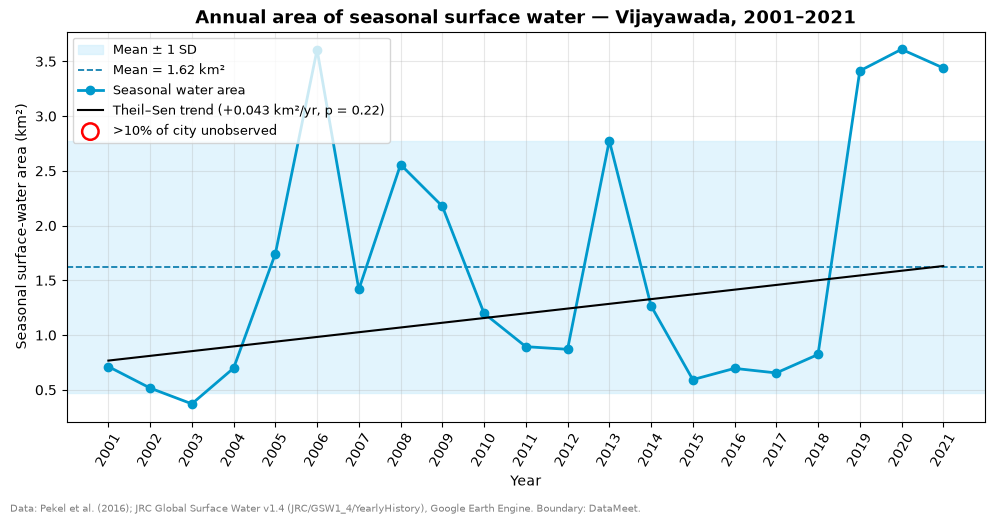

In [14]:
fig, ax = plt.subplots(figsize=(10, 5.2))

ax.axhspan(mean_s - sd_s, mean_s + sd_s, color="#cfeefc", alpha=0.6,
           label="Mean ± 1 SD")
ax.axhline(mean_s, color="#0077aa", ls="--", lw=1.2, label=f"Mean = {mean_s:.2f} km²")

ax.plot(yrs, s, marker="o", color=SEASONAL_COLOR.replace("#00c2ff", "#0099cc"),
        lw=2, label="Seasonal water area")

trend_line = sen[1] + sen[0] * yrs
ax.plot(yrs, trend_line, color="black", lw=1.5,
        label=f"Theil–Sen trend ({sen[0]:+.3f} km²/yr, p = {p_tau:.2f})")

# flag years with a lot of missing data
flag = df["pct_nodata"] > 10
ax.scatter(yrs[flag], s[flag], s=140, facecolors="none", edgecolors="red",
           lw=1.8, label=">10% of city unobserved", zorder=5)

ax.set_title("Annual area of seasonal surface water — Vijayawada, 2001–2021",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Seasonal surface-water area (km²)")
ax.set_xticks(yrs)
ax.set_xticklabels(yrs, rotation=60)
ax.grid(alpha=0.3)
ax.legend(frameon=True, fontsize=9, loc="best")

fig.text(0.01, 0.005, f"Data: {DATASET_SOURCE}. Boundary: DataMeet.",
         fontsize=7, color="gray")
plt.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(os.path.join(OUT_DIR, "graph_seasonal_water_area.png"), dpi=200)
plt.show()

###  Graph 2 — Seasonal versus permanent water, and data coverage

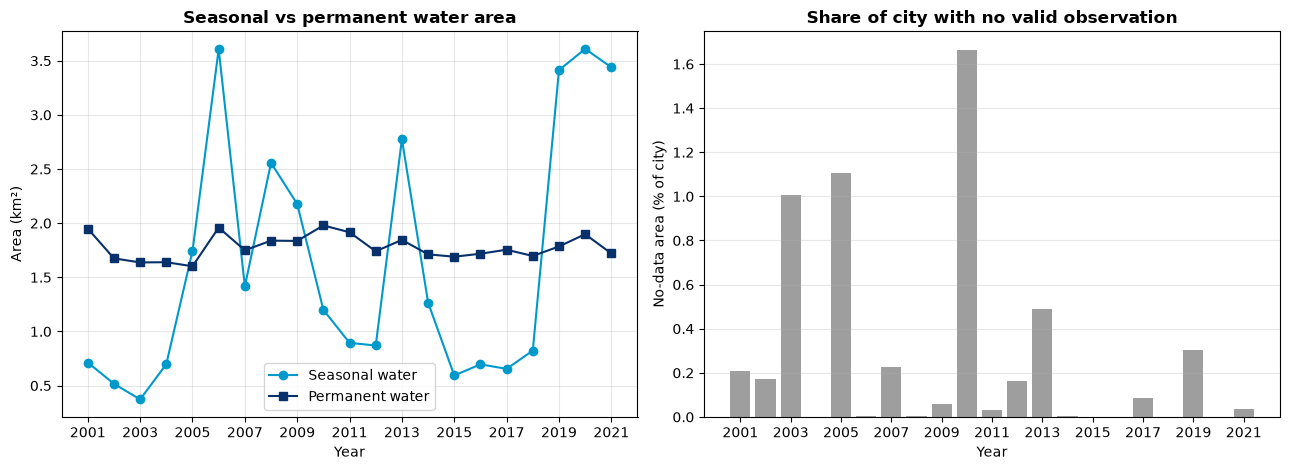

Correlation between seasonal-water area and no-data share: -0.12
Correlation between seasonal and permanent water area: +0.39


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
ax.plot(yrs, df["seasonal_km2"], marker="o", color="#0099cc", label="Seasonal water")
ax.plot(yrs, df["permanent_km2"], marker="s", color=PERMANENT_COLOR, label="Permanent water")
ax.set_title("Seasonal vs permanent water area", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Area (km²)")
ax.set_xticks(yrs[::2])
ax.grid(alpha=0.3)
ax.legend()

ax = axes[1]
ax.bar(yrs, df["pct_nodata"], color="#9e9e9e")
ax.set_title("Share of city with no valid observation", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("No-data area (% of city)")
ax.set_xticks(yrs[::2])
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "graph_permanent_and_nodata.png"), dpi=200)
plt.show()

print("Correlation between seasonal-water area and no-data share: "
      f"{np.corrcoef(df['seasonal_km2'], df['pct_nodata'])[0,1]:+.2f}")
print("Correlation between seasonal and permanent water area: "
      f"{np.corrcoef(df['seasonal_km2'], df['permanent_km2'])[0,1]:+.2f}")

In [16]:
# White background everywhere, light fill inside the city, black boundary line
white_bg = ee.Image.constant(1).visualize(palette=["#ffffff"], min=0, max=1)
city_fill = (
    ee.Image.constant(1).clipToCollection(vijayawada)
    .visualize(palette=["#f5f1e6"], min=0, max=1)
)
outline = (
    ee.Image().byte()
    .paint(featureCollection=vijayawada, color=1, width=2)
    .visualize(palette=["#000000"], min=0, max=1)
)

def compose(layer_vis):
    """white background + city fill + data layer + boundary line"""
    return white_bg.blend(city_fill).blend(layer_vis).blend(outline)


def ee_to_pil(rgb_image, dimensions=900):
    url = rgb_image.getThumbURL({
        "region": region_bounds,
        "dimensions": dimensions,
        "format": "png",
    })
    resp = requests.get(url, timeout=180)
    resp.raise_for_status()
    return Image.open(io.BytesIO(resp.content))

### Static maps of water class in selected years

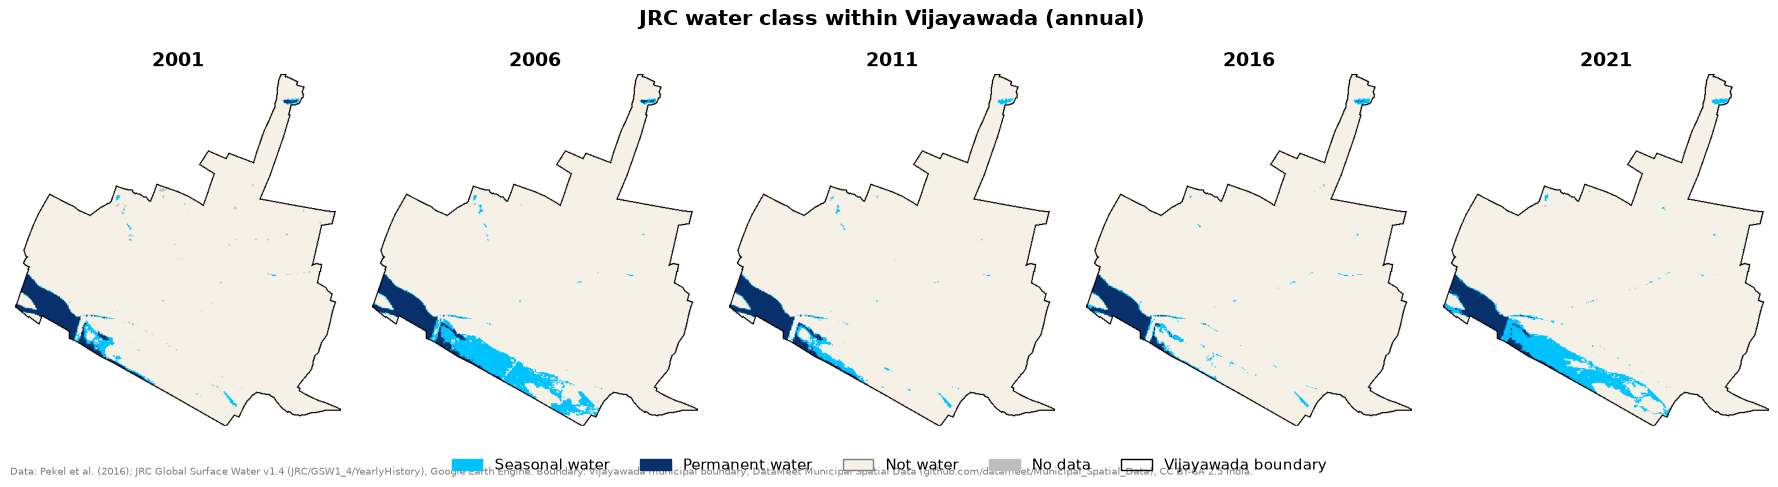

In [17]:
SELECTED_YEARS = [2001, 2006, 2011, 2016, 2021]

fig, axes = plt.subplots(1, len(SELECTED_YEARS), figsize=(18, 4.8))

for ax, yr in zip(axes, SELECTED_YEARS):
    img = ee.Image(annual_water.filter(ee.Filter.eq("year", yr)).first())
    layer = img.visualize(**class_vis)
    ax.imshow(ee_to_pil(compose(layer), 600))
    ax.set_title(str(yr), fontsize=14, fontweight="bold")
    ax.axis("off")

handles = [
    mpatches.Patch(color=SEASONAL_COLOR, label="Seasonal water"),
    mpatches.Patch(color=PERMANENT_COLOR, label="Permanent water"),
    mpatches.Patch(color=NOTWATER_COLOR, ec="gray", label="Not water"),
    mpatches.Patch(color=NODATA_COLOR, label="No data"),
    mpatches.Patch(fc="none", ec="black", label="Vijayawada boundary"),
]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=11, frameon=False)
fig.suptitle("JRC water class within Vijayawada (annual)", fontsize=15, fontweight="bold")
fig.text(0.01, 0.01, f"Data: {DATASET_SOURCE}. Boundary: {BOUNDARY_SOURCE}.",
         fontsize=7, color="gray")
plt.tight_layout(rect=(0, 0.08, 1, 0.95))
fig.savefig(os.path.join(OUT_DIR, "map_selected_years.png"), dpi=200)
plt.show()

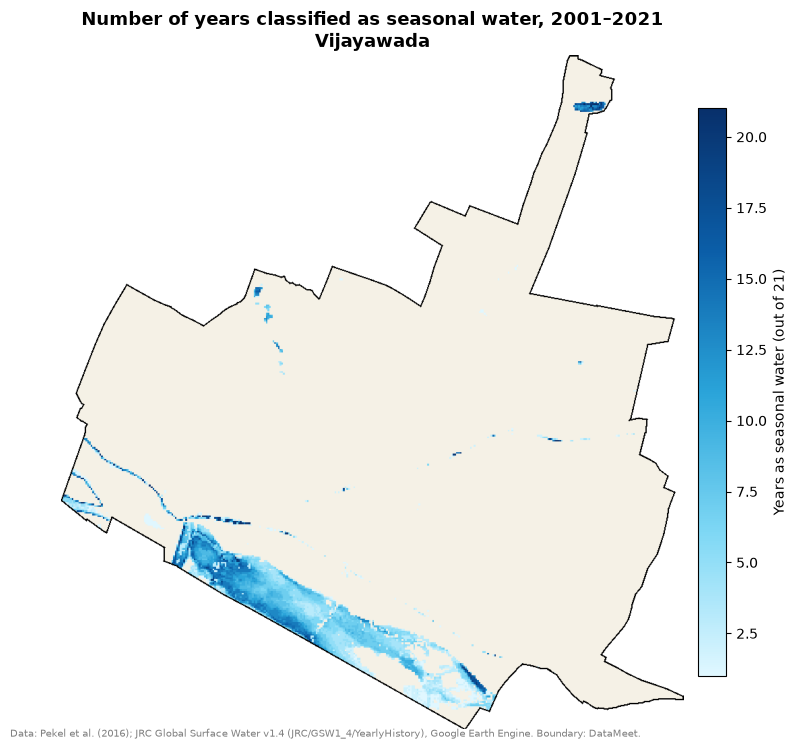

In [18]:
seasonal_flag = annual_water.map(
    lambda img: img.eq(2).copyProperties(img, ["system:time_start", "year"])
)

seasonal_freq = (
    seasonal_flag.sum()
    .rename("years_seasonal")
    .clipToCollection(vijayawada)
)

FREQ_PALETTE = ["#e0f7ff", "#7fd8f5", "#2aa4d9", "#0b5ea8", "#08306b"]
freq_vis = {"min": 1, "max": len(YEARS), "palette": FREQ_PALETTE}

freq_layer = seasonal_freq.updateMask(seasonal_freq.gt(0)).visualize(**freq_vis)
freq_img = ee_to_pil(compose(freq_layer), 1000)

fig, ax = plt.subplots(figsize=(8, 7.5))
ax.imshow(freq_img)
ax.axis("off")
ax.set_title("Number of years classified as seasonal water, 2001–2021\nVijayawada",
             fontsize=13, fontweight="bold")

cmap = LinearSegmentedColormap.from_list("freq", FREQ_PALETTE)
sm = ScalarMappable(norm=Normalize(1, len(YEARS)), cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Years as seasonal water (out of 21)")

fig.text(0.01, 0.01, f"Data: {DATASET_SOURCE}. Boundary: DataMeet.", fontsize=7, color="gray")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "map_seasonal_frequency.png"), dpi=200)
plt.show()

In [19]:
# Numerical summary of the frequency map
area_km2 = ee.Image.pixelArea().divide(1e6)

def area_where(mask_img):
    d = area_km2.multiply(mask_img).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=vijayawada_geom,
        scale=30, maxPixels=1e9, tileScale=4
    )
    return list(d.getInfo().values())[0]

ever = area_where(seasonal_freq.gte(1))
often = area_where(seasonal_freq.gte(11))     # seasonal in more than half the years
always = area_where(seasonal_freq.gte(len(YEARS)))

print(f"Area that was seasonal water in at least 1 year      : {ever:.2f} km²")
print(f"Area that was seasonal water in at least 11 of 21 yrs: {often:.2f} km²")
print(f"Area that was seasonal water in all 21 years         : {always:.2f} km²")
print(f"Mean annual seasonal area / area ever seasonal       : {mean_s/ever:.2f}")

Area that was seasonal water in at least 1 year      : 4.64 km²
Area that was seasonal water in at least 11 of 21 yrs: 1.13 km²
Area that was seasonal water in all 21 years         : 0.03 km²
Mean annual seasonal area / area ever seasonal       : 0.35


### Change map: early versus late period

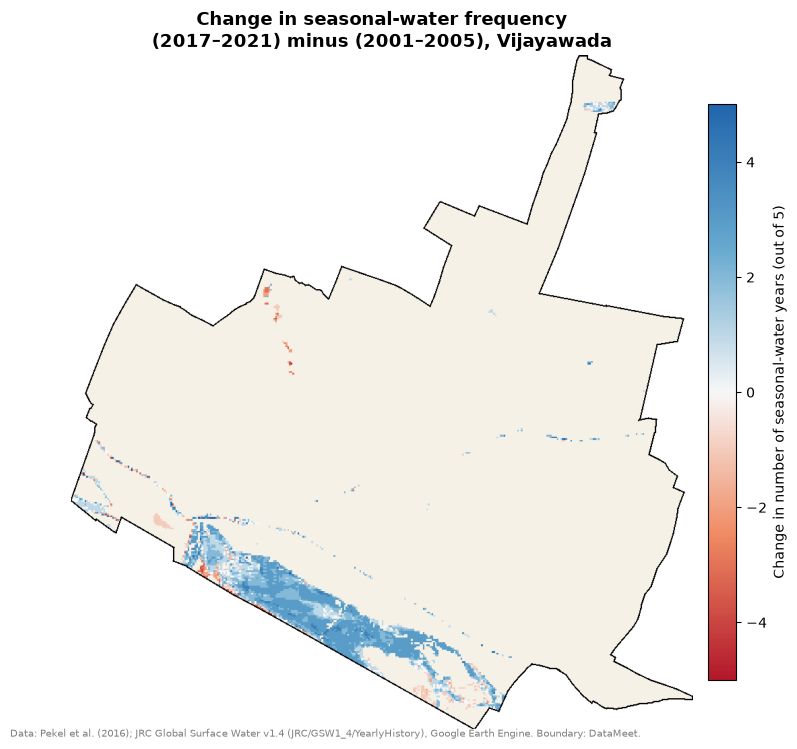

Area where seasonal-water frequency increased: 3.47 km²
Area where seasonal-water frequency decreased: 0.44 km²


In [20]:
early_img = seasonal_flag.filter(ee.Filter.lte("year", START_YEAR + 4)).sum()
late_img = seasonal_flag.filter(ee.Filter.gte("year", END_YEAR - 4)).sum()

change = late_img.subtract(early_img).rename("change").clipToCollection(vijayawada)
has_signal = early_img.add(late_img).gt(0)

CHANGE_PALETTE = ["#b2182b", "#ef8a62", "#f7f7f7", "#67a9cf", "#2166ac"]
change_vis = {"min": -5, "max": 5, "palette": CHANGE_PALETTE}

change_layer = change.updateMask(has_signal).visualize(**change_vis)
change_pil = ee_to_pil(compose(change_layer), 1000)

fig, ax = plt.subplots(figsize=(8, 7.5))
ax.imshow(change_pil)
ax.axis("off")
ax.set_title("Change in seasonal-water frequency\n(2017–2021) minus (2001–2005), Vijayawada",
             fontsize=13, fontweight="bold")

cmap = LinearSegmentedColormap.from_list("chg", CHANGE_PALETTE)
sm = ScalarMappable(norm=Normalize(-5, 5), cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Change in number of seasonal-water years (out of 5)")

fig.text(0.01, 0.01, f"Data: {DATASET_SOURCE}. Boundary: DataMeet.", fontsize=7, color="gray")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "map_seasonal_change.png"), dpi=200)
plt.show()

gain = area_where(change.gt(0))
loss = area_where(change.lt(0))
print(f"Area where seasonal-water frequency increased: {gain:.2f} km²")
print(f"Area where seasonal-water frequency decreased: {loss:.2f} km²")

### Interactive time slider

In [21]:
year_labels = [str(y) for y in YEARS]

Map = geemap.Map()
Map.centerObject(vijayawada, 11)
Map.add_basemap("SATELLITE")

Map.add_time_slider(
    water_slider_collection,
    slider_vis,
    region=vijayawada_geom,
    layer_name="Annual surface water",
    labels=year_labels,
    time_interval=1,
    position="bottomright"
)

Map.addLayer(vijayawada, {"color": "white"}, "Vijayawada boundary")

# Legend for the slider layer
Map.add_legend(
    title="Surface water",
    legend_dict={
        "Seasonal water": SEASONAL_COLOR,
        "Permanent water": PERMANENT_COLOR,
    },
    position="bottomleft"
)
Map

Map(center=[16.521661790351352, 80.63998335517861], controls=(WidgetControl(options=['position', 'transparent_…

###  Animated GIF (2001 → 2021)

In [22]:
def make_frame(img):
    layer = img.visualize(**class_vis)
    return (
        compose(layer)
        .copyProperties(img, ["system:time_start", "year"])
    )

gif_collection = annual_water.map(make_frame)

gif_file = os.path.join(OUT_DIR, "Vijayawada_water_class_2001_2021.gif")

video_args = {
    "dimensions": 700,
    "region": region_bounds,
    "framesPerSecond": 2,
    "crs": "EPSG:3857",
    "bands": ["vis-red", "vis-green", "vis-blue"],
    "min": 0,
    "max": 255,
}

geemap.download_ee_video(gif_collection, video_args, gif_file)
print("Saved:", gif_file)

Generating URL...
Please wait ...
The GIF image has been saved to: C:\Users\ANAGHA K N\Desktop\UISA_2026\vijayawada_gsw_outputs\Vijayawada_water_class_2001_2021.gif
Saved: C:\Users\ANAGHA K N\Desktop\UISA_2026\vijayawada_gsw_outputs\Vijayawada_water_class_2001_2021.gif


In [23]:
labelled_gif = os.path.join(OUT_DIR, "Vijayawada_water_class_2001_2021_labelled.gif")

geemap.add_text_to_gif(
    gif_file,
    labelled_gif,
    xy=("5%", "5%"),
    text_sequence=year_labels,
    font_size=30,
    font_color="black",
    add_progress_bar=True,
    progress_bar_color="#0099cc"
)

geemap.show_image(labelled_gif)

Output()

### Interpretation

In [24]:
print("KEY NUMBERS FOR THE WRITE-UP")
print("=" * 60)
print(f"1. City area analysed: {df['total_km2'].iloc[0]:.1f} km² "
      f"(boundary: {BOUNDARY_SOURCE})")
print(f"2. Mean seasonal water: {mean_s:.2f} km² "
      f"({100*mean_s/df['total_km2'].iloc[0]:.1f}% of city area), "
      f"SD {sd_s:.2f} km², CV {cv_s:.0f}%")
print(f"3. Lowest year: {yrs[i_min]} ({s[i_min]:.2f} km²); "
      f"highest year: {yrs[i_max]} ({s[i_max]:.2f} km²); "
      f"ratio max/min = {s[i_max]/max(s[i_min],1e-9):.1f}")
print(f"4. Trend: Theil–Sen {sen[0]:+.3f} km²/yr, Kendall τ = {tau:+.2f}, p = {p_tau:.3f} "
      f"→ {'statistically significant' if p_tau < 0.05 else 'not statistically significant'} at 5%")
print(f"5. First 5 yrs vs last 5 yrs: {early_mean:.2f} → {late_mean:.2f} km² "
      f"({100*(late_mean-early_mean)/early_mean:+.1f}%)")
print(f"6. Persistence: {ever:.2f} km² seasonal in ≥1 year; "
      f"{often:.2f} km² in ≥11 years; {always:.2f} km² in all 21 years")
print(f"7. Data quality: maximum no-data share = {df['pct_nodata'].max():.1f}% "
      f"(year {int(df.loc[df['pct_nodata'].idxmax(), 'year'])})")

KEY NUMBERS FOR THE WRITE-UP
1. City area analysed: 61.5 km² (boundary: Vijayawada municipal boundary, DataMeet Municipal Spatial Data (github.com/datameet/Municipal_Spatial_Data), CC BY-SA 2.5 India)
2. Mean seasonal water: 1.62 km² (2.6% of city area), SD 1.15 km², CV 71%
3. Lowest year: 2003 (0.37 km²); highest year: 2020 (3.61 km²); ratio max/min = 9.7
4. Trend: Theil–Sen +0.043 km²/yr, Kendall τ = +0.20, p = 0.219 → not statistically significant at 5%
5. First 5 yrs vs last 5 yrs: 0.81 → 2.39 km² (+195.4%)
6. Persistence: 4.64 km² seasonal in ≥1 year; 1.13 km² in ≥11 years; 0.03 km² in all 21 years
7. Data quality: maximum no-data share = 1.7% (year 2010)
